# Simple and Multiple Linear Regression

# Import the required libraries


In [3]:
# Import pandas for creating and handling the dataset
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for drawing graphs
import matplotlib.pyplot as plt

# Import train_test_split to divide data into training and testing sets
from sklearn.model_selection import train_test_split

# Import LinearRegression to build regression models
from sklearn.linear_model import LinearRegression

# Import evaluation metrics
from sklearn.metrics import r2_score, mean_squared_error

# Create a Sample Library Dataset

In [4]:
# Create a sample dataset containing library details
data = {
    "Visitors": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "Available_Books": [100, 120, 140, 160, 180, 200, 220, 240, 260, 280],
    "Opening_Hours": [2, 3, 3, 4, 4, 5, 5, 6, 6, 7],
    "Books_Borrowed": [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
}

# Convert the dataset into a DataFrame
df = pd.DataFrame(data)

# Display the dataset
print("Library Dataset:")
print(df)

Library Dataset:
   Visitors  Available_Books  Opening_Hours  Books_Borrowed
0        10              100              2               5
1        20              120              3              10
2        30              140              3              15
3        40              160              4              20
4        50              180              4              25
5        60              200              5              30
6        70              220              5              35
7        80              240              6              40
8        90              260              6              45
9       100              280              7              50


# Select Input and Output Variables

In [5]:
# Simple Linear Regression: use Visitors as the input
X_simple = df[["Visitors"]]

# Multiple Linear Regression: use three input variables
X_multiple = df[["Visitors", "Available_Books", "Opening_Hours"]]

# Select Books_Borrowed as the output variable
y = df["Books_Borrowed"]

# Display the input and output variables
print("Simple Regression Input:")
print(X_simple.head())

print("\nOutput Variable:")
print(y.head())

Simple Regression Input:
   Visitors
0        10
1        20
2        30
3        40
4        50

Output Variable:
0     5
1    10
2    15
3    20
4    25
Name: Books_Borrowed, dtype: int64


# Split the Data into Training and Testing Sets

In [6]:
# Split the simple regression data
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Split the multiple regression input data
X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

# Display the training and testing data sizes
print("Training data size:", len(X_train_s))
print("Testing data size:", len(X_test_s))

Training data size: 8
Testing data size: 2


# Simple Linear Regression


In [7]:
# Create a Simple Linear Regression model
simple_model = LinearRegression()

# Train the model using training data
simple_model.fit(X_train_s, y_train)

# Predict the number of books borrowed
simple_predictions = simple_model.predict(X_test_s)

# Display the model results
print("--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

# Evaluate the model
print("R2 Score:", r2_score(y_test, simple_predictions))

# Calculate Root Mean Squared Error
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_predictions)))

--- Simple Linear Regression ---
Intercept: 0.0
Coefficient: 0.5
R2 Score: 1.0
RMSE: 0.0


# Multiple Linear Regression

In [8]:
# Create a Multiple Linear Regression model
multiple_model = LinearRegression()

# Train the model using three input variables
multiple_model.fit(X_train_m, y_train)

# Predict the number of books borrowed
multiple_predictions = multiple_model.predict(X_test_m)

# Display the model results
print("--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)

# Evaluate the model
print("R2 Score:", r2_score(y_test, multiple_predictions))

# Calculate Root Mean Squared Error
print("RMSE:", np.sqrt(mean_squared_error(y_test, multiple_predictions)))

--- Multiple Linear Regression ---
Intercept: -16.0
Coefficients: [1.00000000e-01 2.00000000e-01 3.85975973e-16]
R2 Score: 1.0
RMSE: 0.0


# Predict Books Borrowed for New Data

In [9]:
# Create new data for Simple Linear Regression
new_library_simple = pd.DataFrame({
    "Visitors": [60]
})

# Create new data for Multiple Linear Regression
new_library_multiple = pd.DataFrame({
    "Visitors": [60],
    "Available_Books": [200],
    "Opening_Hours": [5]
})

# Predict using Simple Linear Regression
print(
    "Predicted books using Simple Regression:",
    simple_model.predict(new_library_simple)[0]
)

# Predict using Multiple Linear Regression
print(
    "Predicted books using Multiple Regression:",
    multiple_model.predict(new_library_multiple)[0]
)

Predicted books using Simple Regression: 30.0
Predicted books using Multiple Regression: 30.0



# Plot Simple Linear Regression


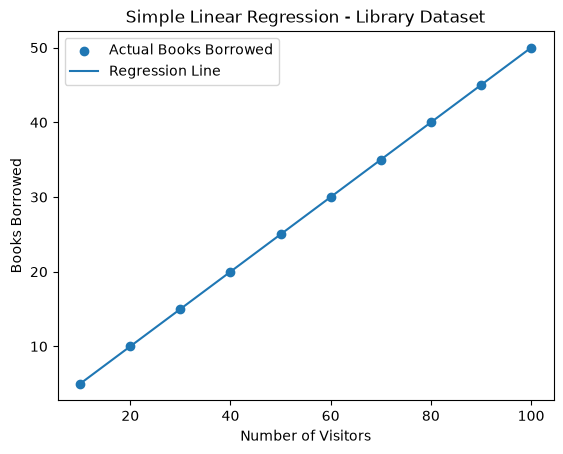

In [10]:
# Display actual library data as a scatter plot
plt.scatter(
    df["Visitors"],
    df["Books_Borrowed"],
    label="Actual Books Borrowed"
)

# Draw the regression line
plt.plot(
    df["Visitors"],
    simple_model.predict(X_simple),
    label="Regression Line"
)

# Add labels and title
plt.xlabel("Number of Visitors")
plt.ylabel("Books Borrowed")
plt.title("Simple Linear Regression - Library Dataset")

# Display the legend
plt.legend()

# Display the graph
plt.show()